# Practical-Exam : Loan_Application

In [1]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
Data  =  pd.read_csv('loan_applications.csv')
Data

,Customer_ID,Age,Income,Loan_Amount,Credit_Score,Loan_Term,Default_Status
0,CUST100000,59,18284,21562,679,24,No
1,CUST100001,49,56263,81226,769,48,No
2,CUST100002,35,55222,12723,648,60,No
3,CUST100003,63,88603,79680,787,60,Yes
4,CUST100004,28,66675,32231,667,48,No
...,...,...,...,...,...,...,...
4995,CUST104995,21,50652,26648,658,84,No
4996,CUST104996,49,15000,16305,648,84,No
4997,CUST104997,42,72746,51046,764,72,No
4998,CUST104998,36,83083,84937,739,60,No


In [3]:
Data.shape

(5000, 7)

In [4]:
Data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Customer_ID     5000 non-null   str  
 1   Age             5000 non-null   int64
 2   Income          5000 non-null   int64
 3   Loan_Amount     5000 non-null   int64
 4   Credit_Score    5000 non-null   int64
 5   Loan_Term       5000 non-null   int64
 6   Default_Status  5000 non-null   str  
dtypes: int64(5), str(2)
memory usage: 273.6 KB


In [5]:
Data.head()

,Customer_ID,Age,Income,Loan_Amount,Credit_Score,Loan_Term,Default_Status
0,CUST100000,59,18284,21562,679,24,No
1,CUST100001,49,56263,81226,769,48,No
2,CUST100002,35,55222,12723,648,60,No
3,CUST100003,63,88603,79680,787,60,Yes
4,CUST100004,28,66675,32231,667,48,No


In [6]:
Data.tail()

,Customer_ID,Age,Income,Loan_Amount,Credit_Score,Loan_Term,Default_Status
4995,CUST104995,21,50652,26648,658,84,No
4996,CUST104996,49,15000,16305,648,84,No
4997,CUST104997,42,72746,51046,764,72,No
4998,CUST104998,36,83083,84937,739,60,No
4999,CUST104999,61,29488,26456,699,36,No


# Part A : Theory(Short-Questions)

## 1. Explain **Mean,Meadian,Mode** in the context of customer income.

### Mean

- Sum of all values / count . Its very highly sensitive to outliers.
- Formula : Mean = Σx / n (Formula to find the mean)

### Median 

- Middle value when sorted.
- Good for skewed income data.

### Mode

- Most frequently occuring value. 
- Useful for categorical data.

## 2.Differentiate between **Std.Deviation** and **Variance** using loan amounts.

- **Variance** and **standard deviation** both measure how spread out data is from the mean, but they differ in calculation and units.

- **Variance** is the average of the squared differences from the mean, resulting in squared units (e.g., $mm^2$), which makes it mathematically convenient for statistical theory but harder to interpret directly.

- **Standard deviation** is the square root of the variance, returning the measure to the original units of the data (e.g., $mm$).  
- This makes standard deviation more practical for understanding the actual dispersion of data points relative to the mean in real-world contexts.

## 3.What is **Random Variable** ? Give one example from dataset.

- A numerical quantity whose value depends on the outcomes of a random phenomenon.

#### Example : 

- LoanDefault → Discrete RV: {0, 1}
- Income → Continuous RV: any value in a range
- CreditScore → Discrete RV: 300–850

## 4.Explain **Conditional Probability** in terms of loan defaults.

- Conditional probability measures the likelihood of an event **A**,  
given that another event **B** has occurred.

- Formula : **P(A | B) = P(A ∩ B) / P(B)**

- P(Default) = 25.5%
- P(Default | Unemployed) = 28.6% → Unemployed customers default more!

## 5.Define **bayes Theorem** and mention how banks can apply it.

- P(Default | Low Credit Score) = 23.2% (calculated via Bayes)
- Formula: P(A|B) = [P(B|A) × P(A)] / P(B)
- Banks use this to update default risk given new info like credit score.

## 6.Differentiate **Empirical Probability** and **Theoretical Probability** with examples.

- **Theoretical probability** based on mathematical logic and assumption that all outcomes are equally likely.No data collection is required.

- **Empirical Probability** Probability based on real-world data or actual observation from experiments or Dataests.

### Eaxmples :

- **Theoretical** : For a fair coin, there are 2 equally likely outcomes (Heads, Tails). The theoretical probability of Heads is 1/2 or 0.5.

- **Empirical** : If you toss a coin 100 times and it lands on Heads 56 times, the empirical probability is 56/100 or 0.56.

## 7.What is **Poisson Distribution** ? Give a business example.

- When we stop measuring continuous variables and start counting a fixed interval , we need the Poisson distirbution.



### Example : 

- Scenario: avg λ = 3 defaults/day
- P(exactly 2 defaults) = 22.4%, P(exactly 3) = 22.4%
- Formula: P(X=k) = (λᵏ × e⁻λ) / k!

## Write a short note on **Eigen Values** and **Eigen Vectors** in data analysis.

**EigenValues** : 
For a square matrix A, a scalar λ (lambda) is called an eigenvalue if there exists a non-zero vector v such that: Av = λv

- This means: multiplying matrix A by vector v gives the same result as simply scaling v by λ. The matrix transforms the vector, but it doesn't rotate it — only stretches or shrinks it.

- The Charactristic of equations : 

Rearranging Av = λv:

Av − λv = 0

(A − λI)v = 0

For a non-trivial solution (v ≠ 0), the matrix (A − λI) must be singular, meaning:

det(A − λI) = 0

**EigenVectors** :
Once we have the eigenvalues λ, we substitute each one back into: (A − λI)v = 0 and solve for v. 
- This vector v is called the Eigenvector. 
- It is the special direction in which the matrix A only scales the vector — it does not rotate or change its direction.
- Key Rule: Eigenvectors are always non-zero vectors. The zero vector is never an eigenvector.

# Part B : Practical

## Step 1 : Central Tendency & Dispersion

- Find Mean,Median,Mode

In [7]:
Income = Data["Income"]

print(f"Mean of Income : {Income.mean():,.0f}")
print(f"Median of Income : {Income.median():,.0f}")
print(f"Mode of Income : {Income.mode()[0]:,.0f}")

Mean of Income : 59,691
Median of Income : 59,332
Mode of Income : 15,000


- Calculate Range,Variance & Std.Deviation

In [8]:
Range = Income.max() - Income.min()
print(f"Range : {Range :,.0f}")
print(f"Variance : {Income.var():,.0f}")
print(f"Standard Deviation : {Income.std():,.0f}")

Range : 110,528
Variance : 397,150,572
Standard Deviation : 19,929


## Step 2 : Probability & Events

- Compute probability of loan default

In [9]:
Total_customers = len(Data)
Defaulted_customers = len(Data[Data["Default_Status"] == "Yes"])
p_default = Defaulted_customers / Total_customers

print(f"Total Customers: {Total_customers}")
print(f"Defaulted Customers: {Defaulted_customers}")
print(f"Probability of Default: {p_default}")
print(f"Probability of Default in %: {p_default * 100:.2f}%")

Total Customers: 5000
Defaulted Customers: 578
Probability of Default: 0.1156
Probability of Default in %: 11.56%


- Create a contingency table between Default_status and Credit_Score

In [10]:
contingency_table = pd.crosstab(Data["Default_Status"], Data["Credit_Score"], margins=True)
contingency_table

Credit_Score,342,369,397,400,401,408,417,419,425,426,...,842,843,844,845,846,847,848,849,850,All
Default_Status,,,,,,,,,,,,,,,,,,,,,
No,0,1,1,1,1,0,0,1,1,0,...,4,2,1,2,5,6,1,2,146,4422
Yes,1,0,0,0,0,1,1,0,0,1,...,0,1,0,0,1,0,1,0,9,578
All,1,1,1,1,1,1,1,1,1,1,...,4,3,1,2,6,6,2,2,155,5000


- Compute conditional probability : P(Default | Credit_Score < 600)

In [11]:
low_credit_customers = Data[Data["Credit_Score"] < 600]
total_low_credit = len(low_credit_customers)
defaulted_low_credit = len(low_credit_customers[low_credit_customers["Default_Status"] == "Yes"])
p_default_given_low_credit = defaulted_low_credit / total_low_credit

print(f"Customers with Credit Score < 600: {total_low_credit}")
print(f"Defaulted Customers (Credit Score < 600): {defaulted_low_credit}")
print(f"P(Default | Credit_Score < 600): {p_default_given_low_credit}")
print(f"P(Default | Credit_Score < 600) in %: {p_default_given_low_credit * 100:.2f}%")

Customers with Credit Score < 600: 945
Defaulted Customers (Credit Score < 600): 254
P(Default | Credit_Score < 600): 0.2687830687830688
P(Default | Credit_Score < 600) in %: 26.88%


## Step 3 : Distribution & Visualization

- Plot **Histogram** of Credit_Score with **Gaussian Distribution** curve.

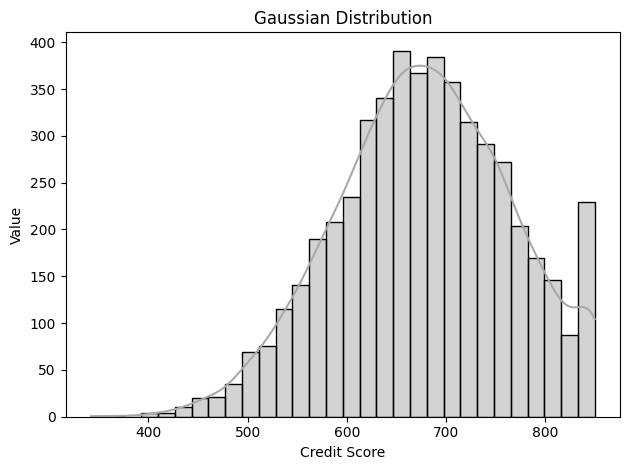

In [12]:
C_Score = Data["Credit_Score"]

plt.figure()
sns.histplot(C_Score,bins=30,color="darkgrey",kde=True)
plt.title("Gaussian Distribution")
plt.xlabel("Credit Score")
plt.ylabel("Value")
plt.tight_layout()
plt.show()

- Check **Skewness** & **Kurtosis** of Loan_Amount.

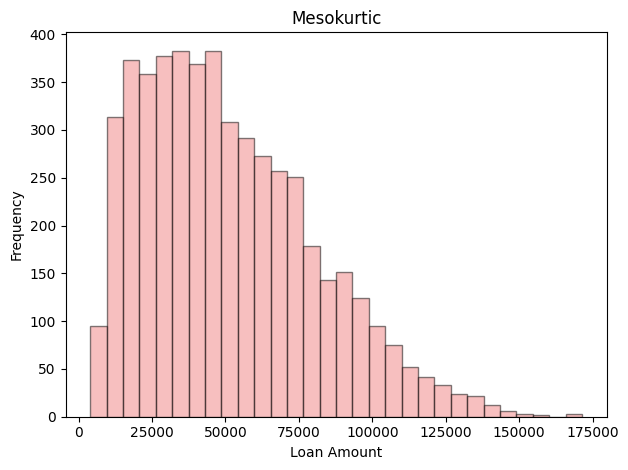

In [13]:
L_Amount = Data["Loan_Amount"]

plt.figure()
plt.hist(L_Amount,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Mesokurtic")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

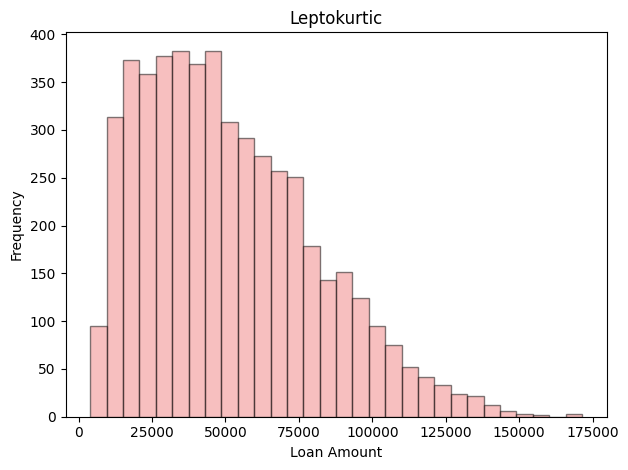

In [14]:
plt.figure()
plt.hist(L_Amount,bins=30,color="lightcoral",edgecolor="black",alpha=0.5)
plt.title("Leptokurtic")
plt.xlabel("Loan Amount")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

- Draw a **Q-Q Plot** for income.

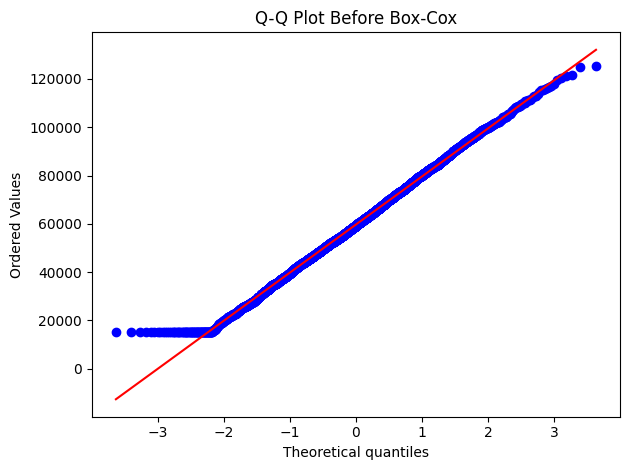

In [15]:
Income = Data["Income"]

plt.figure()
stats.probplot(Income, dist="norm", plot=plt)
plt.title("Q-Q Plot Before Box-Cox")
plt.tight_layout()
plt.show()

## Step 4 : linear Algebra Application

- Perform **Dot Product** between two customers.

In [16]:
In_and_L_Amount = Data[["Income", "Loan_Amount"]].head()
In_and_L_Amount

,Income,Loan_Amount
0,18284,21562
1,56263,81226
2,55222,12723
3,88603,79680
4,66675,32231


In [17]:
Customer1 = np.array(In_and_L_Amount.iloc[0], dtype=float)
Customer2 = np.array(In_and_L_Amount.iloc[1], dtype=float)
Customer3 = np.array(In_and_L_Amount.iloc[2], dtype=float)
Customer4 = np.array(In_and_L_Amount.iloc[3], dtype=float)
Customer5 = np.array(In_and_L_Amount.iloc[4], dtype=float)

print("Customer1:", Customer1)
print("Customer2:", Customer2)
print("Customer3:", Customer3)
print("Customer4:", Customer4)
print("Customer5:", Customer5)

Customer1: [18284. 21562.]
Customer2: [56263. 81226.]
Customer3: [55222. 12723.]
Customer4: [88603. 79680.]
Customer5: [66675. 32231.]


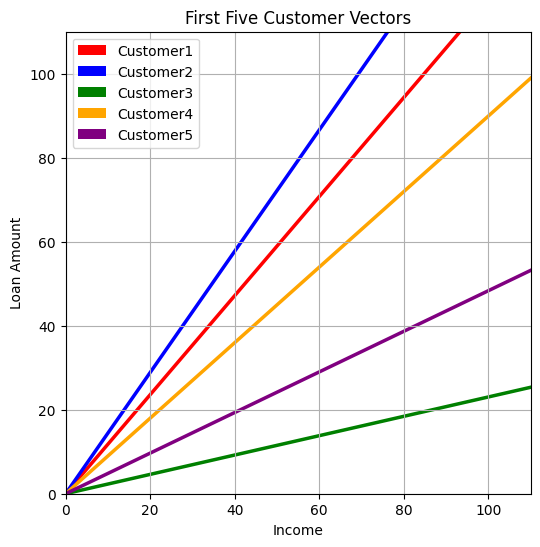

In [18]:
plt.figure(figsize=(6,6))

plt.quiver(0,0,Customer1[0],Customer1[1],angles='xy',scale_units='xy',scale=1,color='red',label='Customer1')
plt.quiver(0,0,Customer2[0],Customer2[1],angles='xy',scale_units='xy',scale=1,color='blue',label='Customer2')
plt.quiver(0,0,Customer3[0],Customer3[1],angles='xy',scale_units='xy',scale=1,color='green',label='Customer3')
plt.quiver(0,0,Customer4[0],Customer4[1],angles='xy',scale_units='xy',scale=1,color='orange',label='Customer4')
plt.quiver(0,0,Customer5[0],Customer5[1],angles='xy',scale_units='xy',scale=1,color='purple',label='Customer5')
plt.xlim(0, 110)
plt.ylim(0, 110)

plt.xlabel("Income")
plt.ylabel("Loan Amount")
plt.title("First Five Customer Vectors")
plt.grid(True)
plt.legend()
plt.show()

In [19]:
dot_product = np.dot(Customer1, Customer2)
print("Dot Product =", dot_product)

Dot Product = 2780107704.0


- Find **Norm 2** of customer's finanicial vector.

In [20]:
Customer1 = np.array(In_and_L_Amount.iloc[0], dtype=float)
Customer2 = np.array(In_and_L_Amount.iloc[1], dtype=float)
Customer3 = np.array(In_and_L_Amount.iloc[2], dtype=float)
Customer4 = np.array(In_and_L_Amount.iloc[3], dtype=float)
Customer5 = np.array(In_and_L_Amount.iloc[4], dtype=float)

Customer1_L2 = np.linalg.norm(Customer1, ord=2)
Customer2_L2 = np.linalg.norm(Customer2, ord=2)
Customer3_L2 = np.linalg.norm(Customer3, ord=2)
Customer4_L2 = np.linalg.norm(Customer4, ord=2)
Customer5_L2 = np.linalg.norm(Customer5, ord=2)

print(f"{'Customer':<12} {'Vector':<30} {'Norm-2':>12}")
print()

print(f"{'Customer1':<12} {str(Customer1):<30} {Customer1_L2:>12.2f}")
print(f"{'Customer2':<12} {str(Customer2):<30} {Customer2_L2:>12.2f}")
print(f"{'Customer3':<12} {str(Customer3):<30} {Customer3_L2:>12.2f}")
print(f"{'Customer4':<12} {str(Customer4):<30} {Customer4_L2:>12.2f}")
print(f"{'Customer5':<12} {str(Customer5):<30} {Customer5_L2:>12.2f}")

Customer     Vector                               Norm-2

Customer1    [18284. 21562.]                    28270.56
Customer2    [56263. 81226.]                    98808.85
Customer3    [55222. 12723.]                    56668.72
Customer4    [88603. 79680.]                   119161.21
Customer5    [66675. 32231.]                    74056.69


- Calculate the **Angle** between two customer's vectors.

In [21]:
magnitude_Customer1 = np.linalg.norm(Customer1)
magnitude_Customer2 = np.linalg.norm(Customer2)

cos_theta = dot_product / (magnitude_Customer1 * magnitude_Customer2)

angle_radian = np.arccos(cos_theta)

print("Angle in Radians:")
print(angle_radian)

angle_degree = np.degrees(angle_radian)

print("\nAngle in Degrees:")
print(angle_degree)

Angle in Radians:
0.09752518079575305

Angle in Degrees:
5.5877812558469575
